# Emotion Recognition from Text and Facial Images: Master Notebook

This one file does everything: trains all models, saves them to Google Drive, and runs the final two tab web app.



In [ ]:
!pip install -q transformers accelerate gensim streamlit
!pip install -q datasets==2.19.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 129.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 97.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.0/542.0 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.0/172.0 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 14.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.3.1 which is incompatible.


## 0. Setup

In [ ]:
import io
import json
import os
import pickle
import re
import subprocess
import sys
import time
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import DataLoader, Dataset, TensorDataset

FORCE_RETRAIN_TEXT = False
FORCE_RETRAIN_IMAGE = False
RUN_LLM_EXPERIMENTS = False

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/emotion_project"
except Exception:
    SAVE_DIR = "/content/emotion_project"
os.makedirs(SAVE_DIR, exist_ok=True)

BERT_DIR = f"{SAVE_DIR}/distilbert"
LSTM_PATH = f"{SAVE_DIR}/lstm_model.pt"
WORD2IDX_PATH = f"{SAVE_DIR}/word2idx.pkl"
TEXT_CLASSES_PATH = f"{SAVE_DIR}/text_classes.pkl"
CNN_PATH = f"{SAVE_DIR}/cnn_model.pt"
RESNET_PATH = f"{SAVE_DIR}/resnet_model.pt"
CBAM_PATH = f"{SAVE_DIR}/resnet_cbam_model.pt"
IMG_CLASSES_PATH = f"{SAVE_DIR}/image_classes.pkl"
RESULTS_PATH = f"{SAVE_DIR}/results.json"
TEXT_FLAG = f"{SAVE_DIR}/text_done.flag"
IMAGE_FLAG = f"{SAVE_DIR}/image_done.flag"

label_names = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

TEXT_ORDER = [
    "Logistic Regression",
    "Feedforward NN",
    "LSTM",
    "DistilBERT",
    "Zero-shot BART (200 samples)",
    "Qwen2.5-1.5B (200 samples)",
    "TinyLlama-1.1B (200 samples)",
]
IMAGE_ORDER = ["Custom CNN", "ResNet18", "ResNet18 + CBAM"]

RECORDED_LLM = {
    "Zero-shot BART (200 samples)": {"accuracy": 24.0, "macro_f1": None, "note": "recorded from earlier run"},
    "Qwen2.5-1.5B (200 samples)": {"accuracy": 50.0, "macro_f1": None, "note": "recorded from earlier run"},
    "TinyLlama-1.1B (200 samples)": {"accuracy": 10.0, "macro_f1": None, "note": "recorded from earlier run"},
}

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
np.random.seed(42)


def load_results():
    if os.path.exists(RESULTS_PATH):
        with open(RESULTS_PATH) as f:
            return json.load(f)
    return {"text": {}, "image": {}}


def update_results(section, entries, overwrite=True):
    data = load_results()
    for name, values in entries.items():
        if overwrite or name not in data[section]:
            data[section][name] = values
    with open(RESULTS_PATH, "w") as f:
        json.dump(data, f, indent=2)


def show_table(section, order):
    data = load_results()[section]
    rows = []
    for name in order:
        if name in data:
            rows.append({
                "Model": name,
                "Accuracy (%)": data[name]["accuracy"],
                "Macro F1": data[name].get("macro_f1"),
                "Note": data[name].get("note", ""),
            })
    return pd.DataFrame(rows)


def save_confusion(y_true, y_pred, labels, title, filename):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            color = "white" if cm_norm[i, j] > 0.5 else "black"
            ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", color=color, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(f"{SAVE_DIR}/{filename}", dpi=200)
    plt.show()


SKIP_TEXT = os.path.exists(TEXT_FLAG) and not FORCE_RETRAIN_TEXT
SKIP_IMAGE = os.path.exists(IMAGE_FLAG) and not FORCE_RETRAIN_IMAGE

print("Device:", device)
print("Save folder:", SAVE_DIR)
print("Text models already saved, training will be skipped:", SKIP_TEXT)
print("Image models already saved, training will be skipped:", SKIP_IMAGE)
if device == "cpu":
    print("WARNING: no GPU found. Change runtime type to T4 GPU, then Run all again.")

Mounted at /content/drive
Device: cuda
Save folder: /content/drive/MyDrive/emotion_project
Text models already saved, training will be skipped: True
Image models already saved, training will be skipped: True


## 1. Text channel (MELD dataset)

In [ ]:
if (not SKIP_TEXT) or RUN_LLM_EXPERIMENTS:
    if not os.path.exists("MELD"):
        subprocess.run(["git", "clone", "https://github.com/declare-lab/MELD.git"], check=True)

    train_df = pd.read_csv("MELD/data/MELD/train_sent_emo.csv")
    test_df = pd.read_csv("MELD/data/MELD/test_sent_emo.csv")

    X_train = train_df["Utterance"].astype(str).tolist()
    y_train = train_df["Emotion"].tolist()
    X_test = test_df["Utterance"].astype(str).tolist()
    y_test = test_df["Emotion"].tolist()

    le = LabelEncoder()
    y_train_enc = le.fit_transform(y_train)
    y_test_enc = le.transform(y_test)
    num_classes = len(le.classes_)

    print(len(X_train), len(X_test))
    print(list(le.classes_))
    print(pd.Series(y_train).value_counts())
else:
    print("Text models are already saved. Data is not needed.")

9989 2610
[np.str_('anger'), np.str_('disgust'), np.str_('fear'), np.str_('joy'), np.str_('neutral'), np.str_('sadness'), np.str_('surprise')]
neutral     4710
joy         1743
surprise    1205
anger       1109
sadness      683
disgust      271
fear         268
Name: count, dtype: int64


### Baselines: Logistic Regression and Feedforward Neural Network

In [ ]:
if not SKIP_TEXT:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression

    vectorizer = TfidfVectorizer(max_features=5000)
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)

    lr_model = LogisticRegression(max_iter=1000)
    lr_model.fit(X_train_vec, y_train_enc)
    lr_pred = lr_model.predict(X_test_vec)
    lr_accuracy = accuracy_score(y_test_enc, lr_pred)
    lr_f1 = f1_score(y_test_enc, lr_pred, average="macro")
    print("Logistic Regression", lr_accuracy, lr_f1)

    class EmotionNet(nn.Module):
        def __init__(self, num_classes):
            super().__init__()
            self.fc1 = nn.Linear(5000, 256)
            self.dropout = nn.Dropout(0.3)
            self.fc2 = nn.Linear(256, num_classes)

        def forward(self, x):
            x = torch.relu(self.fc1(x))
            x = self.dropout(x)
            return self.fc2(x)

    X_train_tensor = torch.tensor(X_train_vec.toarray(), dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test_vec.toarray(), dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train_enc, dtype=torch.long)

    ffn_model = EmotionNet(num_classes).to(device)
    ffn_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=64, shuffle=True)
    ffn_criterion = nn.CrossEntropyLoss()
    ffn_optimizer = optim.Adam(ffn_model.parameters(), lr=0.001)

    for epoch in range(10):
        ffn_model.train()
        total_loss = 0
        for xb, yb in ffn_loader:
            xb, yb = xb.to(device), yb.to(device)
            ffn_optimizer.zero_grad()
            loss = ffn_criterion(ffn_model(xb), yb)
            loss.backward()
            ffn_optimizer.step()
            total_loss += loss.item()
        print(epoch + 1, total_loss / len(ffn_loader))

    ffn_model.eval()
    with torch.no_grad():
        ffn_pred = torch.argmax(ffn_model(X_test_tensor.to(device)), dim=1).cpu().numpy()
    ffn_accuracy = accuracy_score(y_test_enc, ffn_pred)
    ffn_f1 = f1_score(y_test_enc, ffn_pred, average="macro")
    print("Feedforward NN", ffn_accuracy, ffn_f1)

    update_results("text", {
        "Logistic Regression": {"accuracy": round(lr_accuracy * 100, 2), "macro_f1": round(lr_f1, 4), "note": ""},
        "Feedforward NN": {"accuracy": round(ffn_accuracy * 100, 2), "macro_f1": round(ffn_f1, 4), "note": ""},
    })

Logistic Regression 0.5268199233716475 0.2409712374838497
1 1.5807848082985847
2 1.3466276598584122
3 1.1849491133052072
4 1.063108023564527
5 0.9568636565451409
6 0.8731422750813187
7 0.8027741385113661
8 0.7426046474724058
9 0.6938970718224338
10 0.6550507849189127
Feedforward NN 0.47586206896551725 0.2966994774125572


### LSTM with GloVe word vectors and class weights

In [ ]:
if not SKIP_TEXT:
    import gensim.downloader as api

    def simple_tokenize(text):
        text = text.lower()
        text = re.sub(r"[^a-z0-9' ]", " ", text)
        return text.split()

    counter = Counter()
    for sent in X_train:
        counter.update(simple_tokenize(sent))

    VOCAB_SIZE = 8000
    most_common = counter.most_common(VOCAB_SIZE - 2)
    word2idx = {word: idx + 2 for idx, (word, _) in enumerate(most_common)}
    word2idx["<pad>"] = 0
    word2idx["<unk>"] = 1

    MAX_LEN = 30

    def encode(text):
        tokens = simple_tokenize(text)
        ids = [word2idx.get(tok, 1) for tok in tokens[:MAX_LEN]]
        ids = ids + [0] * (MAX_LEN - len(ids))
        return ids

    X_train_ids = torch.tensor([encode(t) for t in X_train], dtype=torch.long)
    X_test_ids = torch.tensor([encode(t) for t in X_test], dtype=torch.long)
    y_train_t = torch.tensor(y_train_enc, dtype=torch.long)

    glove_vectors = api.load("glove-wiki-gigaword-100")
    embed_dim = 100
    embedding_matrix = np.zeros((len(word2idx), embed_dim))
    for word, idx in word2idx.items():
        if word in glove_vectors:
            embedding_matrix[idx] = glove_vectors[word]
        else:
            embedding_matrix[idx] = np.random.normal(scale=0.6, size=(embed_dim,))
    embedding_matrix[0] = np.zeros(embed_dim)
    embedding_tensor = torch.tensor(embedding_matrix, dtype=torch.float)

    class LSTMClassifier(nn.Module):
        def __init__(self, embedding_matrix, hidden_dim=256, num_classes=7):
            super().__init__()
            vocab_size, embed_dim = embedding_matrix.shape
            self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=False, padding_idx=0)
            self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=2, batch_first=True, bidirectional=True, dropout=0.3)
            self.dropout = nn.Dropout(0.4)
            self.fc = nn.Linear(hidden_dim * 2, num_classes)

        def forward(self, x):
            embedded = self.embedding(x)
            _, (hidden, _) = self.lstm(embedded)
            combined = torch.cat((hidden[-2], hidden[-1]), dim=1)
            out = self.dropout(combined)
            return self.fc(out)

    class SeqDataset(Dataset):
        def __init__(self, X, y):
            self.X = X
            self.y = y

        def __len__(self):
            return len(self.X)

        def __getitem__(self, idx):
            return self.X[idx], self.y[idx]

    lstm_model = LSTMClassifier(embedding_tensor, num_classes=num_classes).to(device)

    balanced_weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_train_enc), y=y_train_enc)
    lstm_weights = torch.tensor(np.power(balanced_weights, 0.5), dtype=torch.float).to(device)

    lstm_loader = DataLoader(SeqDataset(X_train_ids, y_train_t), batch_size=64, shuffle=True)
    lstm_criterion = nn.CrossEntropyLoss(weight=lstm_weights)
    lstm_optimizer = optim.Adam(lstm_model.parameters(), lr=0.001)
    lstm_scheduler = optim.lr_scheduler.StepLR(lstm_optimizer, step_size=5, gamma=0.5)

    for epoch in range(15):
        lstm_model.train()
        total_loss = 0
        for xb, yb in lstm_loader:
            xb, yb = xb.to(device), yb.to(device)
            lstm_optimizer.zero_grad()
            loss = lstm_criterion(lstm_model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(lstm_model.parameters(), max_norm=5)
            lstm_optimizer.step()
            total_loss += loss.item()
        lstm_scheduler.step()
        print(epoch + 1, total_loss / len(lstm_loader))

    lstm_model.eval()
    with torch.no_grad():
        lstm_pred = torch.argmax(lstm_model(X_test_ids.to(device)), dim=1).cpu().numpy()

    lstm_accuracy = accuracy_score(y_test_enc, lstm_pred)
    lstm_f1 = f1_score(y_test_enc, lstm_pred, average="macro")
    print(lstm_accuracy, lstm_f1)
    print(classification_report(y_test_enc, lstm_pred, target_names=le.classes_))

    torch.save(lstm_model.state_dict(), LSTM_PATH)
    with open(WORD2IDX_PATH, "wb") as f:
        pickle.dump(word2idx, f)
    with open(TEXT_CLASSES_PATH, "wb") as f:
        pickle.dump(le.classes_, f)

    update_results("text", {
        "LSTM": {"accuracy": round(lstm_accuracy * 100, 2), "macro_f1": round(lstm_f1, 4), "note": ""},
    })

[==================================================] 100.0% 128.1/128.1MB downloaded
1 1.7813170768652753
2 1.6366954988734737
3 1.5564692992313651
4 1.4597373039099821
5 1.3517274552849448
6 1.2080706259247604
7 1.124240403342399
8 1.0504548143429362
9 0.9807117896474851
10 0.9090127143890235
11 0.7933512181992743
12 0.7457004730488844
13 0.6958321414555714
14 0.6550471116403106
15 0.6072568912414988
0.4409961685823755 0.2941972781810423
              precision    recall  f1-score   support

       anger       0.24      0.24      0.24       345
     disgust       0.17      0.10      0.13        68
        fear       0.06      0.16      0.09        50
         joy       0.38      0.39      0.38       402
     neutral       0.61      0.58      0.60      1256
     sadness       0.26      0.17      0.21       208
    surprise       0.37      0.46      0.41       281

    accuracy                           0.44      2610
   macro avg       0.30      0.30      0.29      2610
weighted avg   

### DistilBERT with class weights

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,1.306590,1.340106,0.639080
2,1.313002,1.311148,0.626437


0.6264367816091954 0.43137393142604025
              precision    recall  f1-score   support

       anger       0.46      0.43      0.45       345
     disgust       0.23      0.13      0.17        68
        fear       0.31      0.10      0.15        50
         joy       0.56      0.57      0.57       402
     neutral       0.78      0.79      0.78      1256
     sadness       0.38      0.30      0.34       208
    surprise       0.50      0.67      0.57       281

    accuracy                           0.63      2610
   macro avg       0.46      0.43      0.43      2610
weighted avg       0.62      0.63      0.62      2610



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

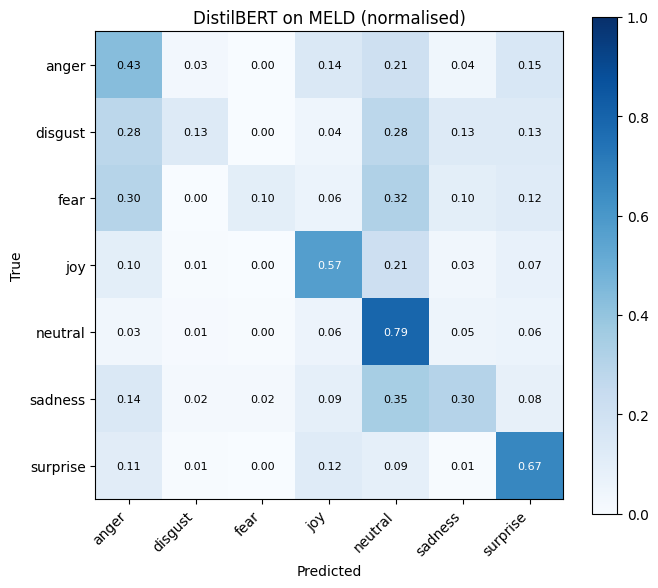

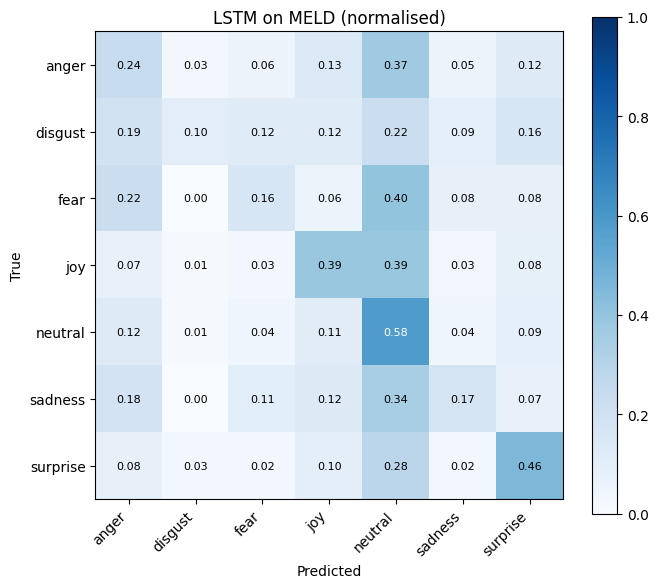

Text models saved to /content/drive/MyDrive/emotion_project


In [ ]:
if not SKIP_TEXT:
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments

    tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
    bert_model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=num_classes)

    class BertDataset(Dataset):
        def __init__(self, texts, labels, tokenizer, max_len=64):
            self.encodings = tokenizer(list(texts), truncation=True, padding=True, max_length=max_len)
            self.labels = labels

        def __len__(self):
            return len(self.labels)

        def __getitem__(self, idx):
            item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
            item["labels"] = torch.tensor(self.labels[idx])
            return item

    train_dataset_bert = BertDataset(X_train, y_train_enc, tokenizer)
    test_dataset_bert = BertDataset(X_test, y_test_enc, tokenizer)

    bert_weights = torch.tensor(np.power(balanced_weights, 0.5), dtype=torch.float)

    class WeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            outputs = model(**inputs)
            logits = outputs.logits
            loss_fct = nn.CrossEntropyLoss(weight=bert_weights.to(logits.device))
            loss = loss_fct(logits, labels)
            return (loss, outputs) if return_outputs else loss

    def bert_metrics(eval_pred):
        logits, labels = eval_pred
        return {"accuracy": accuracy_score(labels, np.argmax(logits, axis=1))}

    training_args = TrainingArguments(
        output_dir="./bert_out",
        num_train_epochs=2,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        learning_rate=2e-5,
        eval_strategy="epoch",
        logging_steps=50,
        save_strategy="no",
        report_to="none",
    )

    trainer = WeightedTrainer(
        model=bert_model,
        args=training_args,
        train_dataset=train_dataset_bert,
        eval_dataset=test_dataset_bert,
        compute_metrics=bert_metrics,
    )
    trainer.train()

    bert_output = trainer.predict(test_dataset_bert)
    bert_pred_labels = np.argmax(bert_output.predictions, axis=1)
    bert_accuracy = accuracy_score(y_test_enc, bert_pred_labels)
    bert_f1 = f1_score(y_test_enc, bert_pred_labels, average="macro")
    print(bert_accuracy, bert_f1)
    print(classification_report(y_test_enc, bert_pred_labels, target_names=le.classes_))

    bert_model.save_pretrained(BERT_DIR)
    tokenizer.save_pretrained(BERT_DIR)

    update_results("text", {
        "DistilBERT": {"accuracy": round(bert_accuracy * 100, 2), "macro_f1": round(bert_f1, 4), "note": ""},
    })

    save_confusion(y_test_enc, bert_pred_labels, list(le.classes_), "DistilBERT on MELD (normalised)", "confusion_distilbert.png")
    save_confusion(y_test_enc, lstm_pred, list(le.classes_), "LSTM on MELD (normalised)", "confusion_lstm.png")

    with open(TEXT_FLAG, "w") as f:
        f.write("ok")
    print("Text models saved to", SAVE_DIR)

### Optional: prompting experiments (BART, Qwen2.5, TinyLlama)

These are off by default because they take a long time and download about 7 GB. Set `RUN_LLM_EXPERIMENTS = True` in the setup cell to run them. When off, the table uses the numbers recorded from the earlier run.

In [ ]:
if RUN_LLM_EXPERIMENTS:
    from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline

    SAMPLE_SIZE = 200
    sample_texts = X_test[:SAMPLE_SIZE]
    sample_true = y_test[:SAMPLE_SIZE]
    candidate_labels = list(le.classes_)

    zero_shot = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=0 if torch.cuda.is_available() else -1)
    zero_shot_preds = [zero_shot(text, candidate_labels)["labels"][0] for text in sample_texts]
    zero_shot_accuracy = accuracy_score(sample_true, zero_shot_preds)
    print("Zero-shot BART", zero_shot_accuracy)

    def prompt_llm_accuracy(model_name):
        llm_tokenizer = AutoTokenizer.from_pretrained(model_name)
        llm_model = AutoModelForCausalLM.from_pretrained(
            model_name,
            dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
            device_map="auto",
        )
        llm_preds = []
        for text in sample_texts:
            prompt = (
                f"Classify the emotion in this sentence into exactly one of these labels: {', '.join(candidate_labels)}.\n"
                f"Sentence: \"{text}\"\n"
                f"Answer with only one word from the label list."
            )
            messages = [{"role": "user", "content": prompt}]
            input_text = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
            inputs = llm_tokenizer(input_text, return_tensors="pt").to(llm_model.device)
            output = llm_model.generate(**inputs, max_new_tokens=10, do_sample=False)
            response = llm_tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
            response = response.strip().lower()
            llm_preds.append(next((label for label in candidate_labels if label in response), candidate_labels[0]))
        del llm_model
        torch.cuda.empty_cache()
        return accuracy_score(sample_true, llm_preds)

    qwen_accuracy = prompt_llm_accuracy("Qwen/Qwen2.5-1.5B-Instruct")
    print("Qwen2.5-1.5B", qwen_accuracy)
    tinyllama_accuracy = prompt_llm_accuracy("TinyLlama/TinyLlama-1.1B-Chat-v1.0")
    print("TinyLlama-1.1B", tinyllama_accuracy)

    update_results("text", {
        "Zero-shot BART (200 samples)": {"accuracy": round(zero_shot_accuracy * 100, 2), "macro_f1": None, "note": "run in this notebook"},
        "Qwen2.5-1.5B (200 samples)": {"accuracy": round(qwen_accuracy * 100, 2), "macro_f1": None, "note": "run in this notebook"},
        "TinyLlama-1.1B (200 samples)": {"accuracy": round(tinyllama_accuracy * 100, 2), "macro_f1": None, "note": "run in this notebook"},
    })
else:
    print("Prompting experiments skipped. Using recorded numbers.")

Prompting experiments skipped. Using recorded numbers.


### Text results table

In [ ]:
update_results("text", RECORDED_LLM, overwrite=False)
show_table("text", TEXT_ORDER)

,Model,Accuracy (%),Macro F1,Note
0,Logistic Regression,52.68,0.2410,
1,Feedforward NN,47.59,0.2967,
2,LSTM,44.10,0.2942,
3,DistilBERT,62.64,0.4314,
4,Zero-shot BART (200 samples),24.00,NaN,recorded from earlier run
5,Qwen2.5-1.5B (200 samples),50.00,NaN,recorded from earlier run
6,TinyLlama-1.1B (200 samples),10.00,NaN,recorded from earlier run


## 2. Image channel (FER2013 dataset)

In [ ]:
if not SKIP_IMAGE:
    from datasets import load_dataset

    ds = load_dataset("Jeneral/fer-2013", trust_remote_code=True)
    print(ds)

    counts = Counter(ds["train"]["labels"])
    for i, name in enumerate(label_names):
        print(name, counts[i])

    def decode_image(example):
        img = Image.open(io.BytesIO(example["img_bytes"])).convert("L").resize((48, 48))
        example["pixels"] = np.array(img, dtype=np.float32) / 255.0
        return example

    ds = ds.map(decode_image)

    img_X_train = torch.tensor(np.stack(ds["train"]["pixels"]), dtype=torch.float32).unsqueeze(1)
    img_y_train = torch.tensor(ds["train"]["labels"], dtype=torch.long)
    img_X_test = torch.tensor(np.stack(ds["test"]["pixels"]), dtype=torch.float32).unsqueeze(1)
    img_y_test = torch.tensor(ds["test"]["labels"], dtype=torch.long)
    print(img_X_train.shape, img_X_test.shape)
else:
    print("Image models are already saved. Data is not needed.")

Generating train split:   0%|          | 0/28709 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7178 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['img_bytes', 'labels'],
        num_rows: 28709
    })
    test: Dataset({
        features: ['img_bytes', 'labels'],
        num_rows: 7178
    })
})
angry 3995
disgust 436
fear 4097
happy 7215
neutral 4965
sad 4830
surprise 3171


Map:   0%|          | 0/28709 [00:00<?, ? examples/s]

Map:   0%|          | 0/7178 [00:00<?, ? examples/s]

torch.Size([28709, 1, 48, 48]) torch.Size([7178, 1, 48, 48])


### Custom CNN (trained from scratch)

In [ ]:
if not SKIP_IMAGE:
    img_weights = torch.tensor(
        compute_class_weight(class_weight="balanced", classes=np.unique(img_y_train.numpy()), y=img_y_train.numpy()),
        dtype=torch.float,
    ).to(device)

    def train_classifier(model, loader, lr, epochs):
        criterion = nn.CrossEntropyLoss(weight=img_weights)
        optimizer = optim.Adam(model.parameters(), lr=lr)
        for epoch in range(epochs):
            model.train()
            total_loss = 0
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device)
                optimizer.zero_grad()
                loss = criterion(model(xb), yb)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
            print(epoch + 1, total_loss / len(loader))

    class SimpleCNN(nn.Module):
        def __init__(self, num_classes=7):
            super().__init__()
            self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
            self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
            self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
            self.pool = nn.MaxPool2d(2, 2)
            self.dropout = nn.Dropout(0.4)
            self.fc1 = nn.Linear(128 * 6 * 6, 256)
            self.fc2 = nn.Linear(256, num_classes)

        def forward(self, x):
            x = self.pool(torch.relu(self.conv1(x)))
            x = self.pool(torch.relu(self.conv2(x)))
            x = self.pool(torch.relu(self.conv3(x)))
            x = x.view(x.size(0), -1)
            x = self.dropout(torch.relu(self.fc1(x)))
            return self.fc2(x)

    cnn_model = SimpleCNN().to(device)
    cnn_loader = DataLoader(TensorDataset(img_X_train, img_y_train), batch_size=64, shuffle=True)
    train_classifier(cnn_model, cnn_loader, 0.001, 15)

    cnn_model.eval()
    with torch.no_grad():
        cnn_pred = torch.argmax(cnn_model(img_X_test.to(device)), dim=1).cpu().numpy()

    cnn_accuracy = accuracy_score(img_y_test.numpy(), cnn_pred)
    cnn_f1 = f1_score(img_y_test.numpy(), cnn_pred, average="macro")
    print(cnn_accuracy, cnn_f1)
    print(classification_report(img_y_test.numpy(), cnn_pred, target_names=label_names))

    torch.save(cnn_model.state_dict(), CNN_PATH)
    with open(IMG_CLASSES_PATH, "wb") as f:
        pickle.dump(label_names, f)

    update_results("image", {
        "Custom CNN": {"accuracy": round(cnn_accuracy * 100, 2), "macro_f1": round(cnn_f1, 4), "note": ""},
    })

1 1.873404870054504
2 1.680790082649027
3 1.5398156427859198
4 1.4360729550200209
5 1.3435538585042635
6 1.2578760574017973
7 1.1746986864138818
8 1.091251204300564
9 1.0355521403336048
10 0.9758326232698818
11 0.9114120143293538
12 0.8475426472640516
13 0.801662859380378
14 0.7472073005010397
15 0.7032463522026428
0.5488994148787963 0.5385062401007298
              precision    recall  f1-score   support

       angry       0.43      0.47      0.45       958
     disgust       0.52      0.58      0.55       111
        fear       0.39      0.43      0.41      1024
       happy       0.75      0.74      0.75      1774
     neutral       0.53      0.45      0.49      1233
         sad       0.42      0.41      0.41      1247
    surprise       0.70      0.71      0.71       831

    accuracy                           0.55      7178
   macro avg       0.54      0.54      0.54      7178
weighted avg       0.55      0.55      0.55      7178



### ResNet18 (pretrained, transfer learning)

In [ ]:
if not SKIP_IMAGE:
    from torchvision.models import ResNet18_Weights, resnet18

    class ResNetFERDataset(Dataset):
        def __init__(self, X, y):
            self.X = X
            self.y = y
            self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
            self.std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

        def __len__(self):
            return len(self.X)

        def __getitem__(self, idx):
            img = self.X[idx]
            img = F.interpolate(img.unsqueeze(0), size=(224, 224), mode="bilinear", align_corners=False).squeeze(0)
            img = img.repeat(3, 1, 1)
            img = (img - self.mean) / self.std
            return img, self.y[idx]

    def predict_images(model):
        loader = DataLoader(ResNetFERDataset(img_X_test, img_y_test), batch_size=64, shuffle=False)
        model.eval()
        collected = []
        with torch.no_grad():
            for xb, _ in loader:
                out = model(xb.to(device))
                collected.extend(torch.argmax(out, dim=1).cpu().numpy())
        return np.array(collected)

    resnet_model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 7)
    resnet_model = resnet_model.to(device)

    resnet_loader = DataLoader(ResNetFERDataset(img_X_train, img_y_train), batch_size=64, shuffle=True, num_workers=2)
    train_classifier(resnet_model, resnet_loader, 0.0001, 6)

    resnet_pred = predict_images(resnet_model)
    resnet_accuracy = accuracy_score(img_y_test.numpy(), resnet_pred)
    resnet_f1 = f1_score(img_y_test.numpy(), resnet_pred, average="macro")
    print(resnet_accuracy, resnet_f1)
    print(classification_report(img_y_test.numpy(), resnet_pred, target_names=label_names))

    torch.save(resnet_model.state_dict(), RESNET_PATH)

    update_results("image", {
        "ResNet18": {"accuracy": round(resnet_accuracy * 100, 2), "macro_f1": round(resnet_f1, 4), "note": ""},
    })

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 137MB/s]


1 1.2576446908884962
2 0.8243801409922092
3 0.537562337146039
4 0.27527066444633796
5 0.12962436474411684
6 0.075292511005162
0.6536639732516021 0.6448666998637702
              precision    recall  f1-score   support

       angry       0.56      0.60      0.58       958
     disgust       0.83      0.61      0.70       111
        fear       0.52      0.52      0.52      1024
       happy       0.82      0.86      0.84      1774
     neutral       0.63      0.57      0.60      1233
         sad       0.55      0.47      0.50      1247
    surprise       0.70      0.85      0.77       831

    accuracy                           0.65      7178
   macro avg       0.66      0.64      0.64      7178
weighted avg       0.65      0.65      0.65      7178



### ResNet18 with CBAM attention

1 1.2653675800176931
2 0.834824136012381
3 0.5830633741842878
4 0.33653228013114567
5 0.167455742222761
6 0.12683984806516388
0.6522708275285595 0.6463695930358718
              precision    recall  f1-score   support

       angry       0.57      0.61      0.59       958
     disgust       0.65      0.68      0.66       111
        fear       0.49      0.55      0.52      1024
       happy       0.90      0.79      0.84      1774
     neutral       0.60      0.58      0.59      1233
         sad       0.53      0.54      0.53      1247
    surprise       0.79      0.80      0.79       831

    accuracy                           0.65      7178
   macro avg       0.65      0.65      0.65      7178
weighted avg       0.66      0.65      0.66      7178



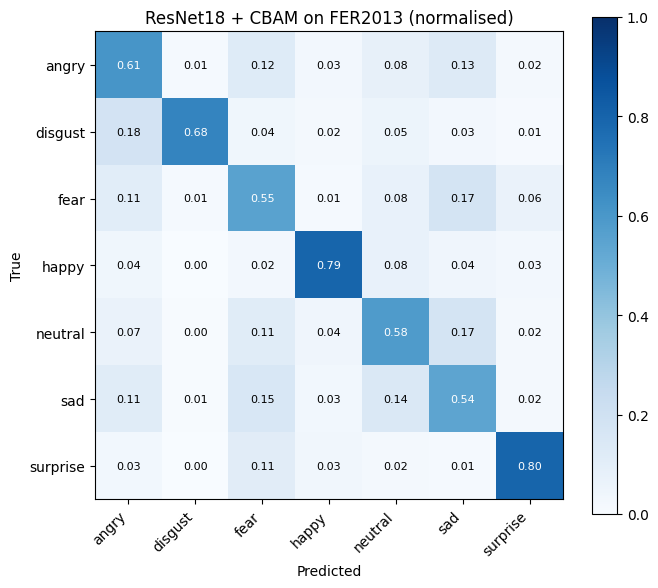

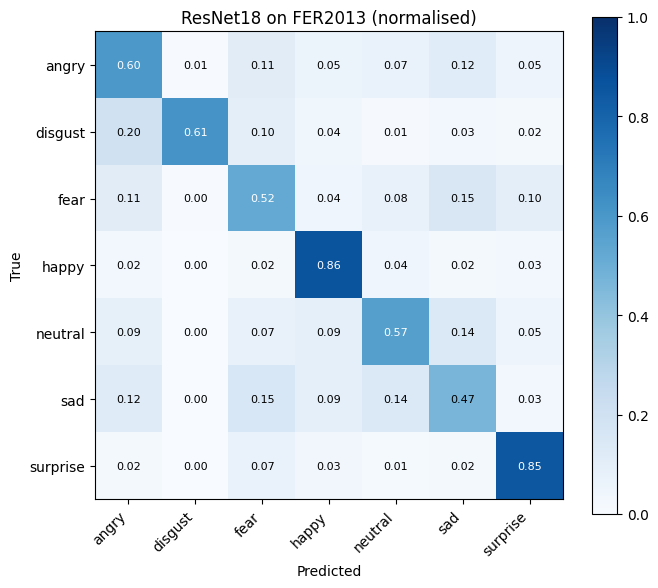

Image models saved to /content/drive/MyDrive/emotion_project


In [ ]:
if not SKIP_IMAGE:
    class ChannelAttention(nn.Module):
        def __init__(self, channels, reduction=16):
            super().__init__()
            self.avg_pool = nn.AdaptiveAvgPool2d(1)
            self.max_pool = nn.AdaptiveMaxPool2d(1)
            self.mlp = nn.Sequential(
                nn.Conv2d(channels, channels // reduction, 1, bias=False),
                nn.ReLU(),
                nn.Conv2d(channels // reduction, channels, 1, bias=False),
            )
            self.sigmoid = nn.Sigmoid()

        def forward(self, x):
            avg_out = self.mlp(self.avg_pool(x))
            max_out = self.mlp(self.max_pool(x))
            return x * self.sigmoid(avg_out + max_out)

    class SpatialAttention(nn.Module):
        def __init__(self):
            super().__init__()
            self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3, bias=False)
            self.sigmoid = nn.Sigmoid()

        def forward(self, x):
            avg_out = torch.mean(x, dim=1, keepdim=True)
            max_out, _ = torch.max(x, dim=1, keepdim=True)
            attn = self.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))
            return x * attn

    class CBAM(nn.Module):
        def __init__(self, channels):
            super().__init__()
            self.channel_attn = ChannelAttention(channels)
            self.spatial_attn = SpatialAttention()

        def forward(self, x):
            x = self.channel_attn(x)
            x = self.spatial_attn(x)
            return x

    cbam_model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    cbam_model.fc = nn.Linear(cbam_model.fc.in_features, 7)
    cbam_model.layer1 = nn.Sequential(cbam_model.layer1, CBAM(64))
    cbam_model.layer2 = nn.Sequential(cbam_model.layer2, CBAM(128))
    cbam_model.layer3 = nn.Sequential(cbam_model.layer3, CBAM(256))
    cbam_model.layer4 = nn.Sequential(cbam_model.layer4, CBAM(512))
    cbam_model = cbam_model.to(device)

    cbam_loader = DataLoader(ResNetFERDataset(img_X_train, img_y_train), batch_size=64, shuffle=True, num_workers=2)
    train_classifier(cbam_model, cbam_loader, 0.0001, 6)

    cbam_pred = predict_images(cbam_model)
    cbam_accuracy = accuracy_score(img_y_test.numpy(), cbam_pred)
    cbam_f1 = f1_score(img_y_test.numpy(), cbam_pred, average="macro")
    print(cbam_accuracy, cbam_f1)
    print(classification_report(img_y_test.numpy(), cbam_pred, target_names=label_names))

    torch.save(cbam_model.state_dict(), CBAM_PATH)

    update_results("image", {
        "ResNet18 + CBAM": {"accuracy": round(cbam_accuracy * 100, 2), "macro_f1": round(cbam_f1, 4), "note": ""},
    })

    save_confusion(img_y_test.numpy(), cbam_pred, label_names, "ResNet18 + CBAM on FER2013 (normalised)", "confusion_resnet_cbam.png")
    save_confusion(img_y_test.numpy(), resnet_pred, label_names, "ResNet18 on FER2013 (normalised)", "confusion_resnet.png")

    with open(IMAGE_FLAG, "w") as f:
        f.write("ok")
    print("Image models saved to", SAVE_DIR)

### Image results table

In [ ]:
show_table("image", IMAGE_ORDER)

,Model,Accuracy (%),Macro F1,Note
0,Custom CNN,54.89,0.5385,
1,ResNet18,65.37,0.6449,
2,ResNet18 + CBAM,65.23,0.6464,


## 3. Final application (one app, two tabs)

The next cell writes the app file. The cell after it starts the app and prints the link.

In [ ]:
APP_CODE = r'''import json
import os
import pickle
import re

import numpy as np
import pandas as pd
import streamlit as st
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision.models import resnet18
from transformers import AutoModelForSequenceClassification, AutoTokenizer

MODEL_DIR = "__MODEL_DIR__"
MAX_LEN = 30


def simple_tokenize(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9' ]", " ", text)
    return text.split()


class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=100, hidden_dim=256, num_classes=7):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=2, batch_first=True, bidirectional=True, dropout=0.3)
        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        combined = torch.cat((hidden[-2], hidden[-1]), dim=1)
        out = self.dropout(combined)
        return self.fc(out)


class SimpleCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(128 * 6 * 6, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(torch.relu(self.fc1(x)))
        return self.fc2(x)


class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(channels // reduction, channels, 1, bias=False),
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.mlp(self.avg_pool(x))
        max_out = self.mlp(self.max_pool(x))
        return x * self.sigmoid(avg_out + max_out)


class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        attn = self.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))
        return x * attn


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.channel_attn = ChannelAttention(channels)
        self.spatial_attn = SpatialAttention()

    def forward(self, x):
        x = self.channel_attn(x)
        x = self.spatial_attn(x)
        return x


def build_resnet():
    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 7)
    return model


def build_resnet_cbam():
    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 7)
    model.layer1 = nn.Sequential(model.layer1, CBAM(64))
    model.layer2 = nn.Sequential(model.layer2, CBAM(128))
    model.layer3 = nn.Sequential(model.layer3, CBAM(256))
    model.layer4 = nn.Sequential(model.layer4, CBAM(512))
    return model


@st.cache_resource
def load_text_models():
    tokenizer = AutoTokenizer.from_pretrained(f"{MODEL_DIR}/distilbert")
    bert = AutoModelForSequenceClassification.from_pretrained(f"{MODEL_DIR}/distilbert")
    bert.eval()

    with open(f"{MODEL_DIR}/text_classes.pkl", "rb") as f:
        classes = pickle.load(f)
    with open(f"{MODEL_DIR}/word2idx.pkl", "rb") as f:
        word2idx = pickle.load(f)

    lstm = LSTMClassifier(vocab_size=len(word2idx), num_classes=len(classes))
    lstm.load_state_dict(torch.load(f"{MODEL_DIR}/lstm_model.pt", map_location="cpu"))
    lstm.eval()

    return tokenizer, bert, lstm, word2idx, [str(c) for c in classes]


@st.cache_resource
def load_image_models():
    with open(f"{MODEL_DIR}/image_classes.pkl", "rb") as f:
        classes = pickle.load(f)

    cnn = SimpleCNN(num_classes=len(classes))
    cnn.load_state_dict(torch.load(f"{MODEL_DIR}/cnn_model.pt", map_location="cpu"))
    cnn.eval()

    resnet = build_resnet()
    resnet.load_state_dict(torch.load(f"{MODEL_DIR}/resnet_model.pt", map_location="cpu"))
    resnet.eval()

    cbam = build_resnet_cbam()
    cbam.load_state_dict(torch.load(f"{MODEL_DIR}/resnet_cbam_model.pt", map_location="cpu"))
    cbam.eval()

    return cnn, resnet, cbam, [str(c) for c in classes]


def load_results():
    path = os.path.join(MODEL_DIR, "results.json")
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return {"text": {}, "image": {}}


RESULTS = load_results()
IMG_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMG_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def accuracy_note(section, name):
    entry = RESULTS.get(section, {}).get(name)
    if entry:
        return f"Test accuracy: {entry['accuracy']}%"
    return ""


def top_prediction(probs, classes):
    idx = int(torch.argmax(probs).item())
    return classes[idx], float(probs[idx].item()) * 100


def show_model(column, title, label, confidence, note):
    with column:
        st.subheader(title)
        st.write(f"Prediction: **{label}**")
        st.write(f"Confidence: {confidence:.2f}%")
        st.progress(int(min(max(confidence, 0), 100)))
        if note:
            st.caption(note)


def predict_lstm(text):
    tokens = simple_tokenize(text)
    ids = [word2idx.get(tok, 1) for tok in tokens[:MAX_LEN]]
    ids = ids + [0] * (MAX_LEN - len(ids))
    x = torch.tensor([ids], dtype=torch.long)
    with torch.no_grad():
        return torch.softmax(lstm_model(x), dim=1)[0]


def predict_bert(text):
    inputs = bert_tokenizer(text, return_tensors="pt", truncation=True, padding=True)
    with torch.no_grad():
        return torch.softmax(bert_model(**inputs).logits, dim=1)[0]


def preprocess_image(image):
    gray = image.convert("L").resize((48, 48))
    arr = np.array(gray, dtype=np.float32) / 255.0
    tensor48 = torch.tensor(arr).unsqueeze(0).unsqueeze(0)
    tensor224 = F.interpolate(tensor48, size=(224, 224), mode="bilinear", align_corners=False)
    tensor224 = tensor224.repeat(1, 3, 1, 1)
    tensor224 = (tensor224 - IMG_MEAN) / IMG_STD
    return tensor48, tensor224


st.set_page_config(page_title="Emotion Recognition", layout="wide")
st.title("Emotion Recognition from Text and Facial Images")
st.caption("Two separate channels. Text and image predictions are never mixed together.")

with st.spinner("Loading models. The first time takes about 30 seconds."):
    bert_tokenizer, bert_model, lstm_model, word2idx, text_classes = load_text_models()
    cnn_model, resnet_model, cbam_model, image_classes = load_image_models()

tab_text, tab_image = st.tabs(["Text Emotion", "Face Emotion"])

with tab_text:
    st.header("Text emotion detector")
    st.caption("LSTM and DistilBERT trained on MELD. Both read the same sentence.")
    text = st.text_area("Type a sentence here", key="text_input")

    if st.button("Analyze text emotion", key="text_button"):
        if text.strip() == "":
            st.warning("Please type something first.")
        else:
            lstm_probs = predict_lstm(text)
            bert_probs = predict_bert(text)
            lstm_label, lstm_conf = top_prediction(lstm_probs, text_classes)
            bert_label, bert_conf = top_prediction(bert_probs, text_classes)

            left, right = st.columns(2)
            show_model(left, "LSTM", lstm_label, lstm_conf, accuracy_note("text", "LSTM"))
            show_model(right, "DistilBERT", bert_label, bert_conf, accuracy_note("text", "DistilBERT"))

            st.markdown("---")
            if lstm_label == bert_label:
                st.success(f"Both models agree: **{bert_label}**")
            else:
                st.info(f"Models disagree. Final answer: **{bert_label}** (DistilBERT, our best text model)")

            chart = pd.DataFrame({"DistilBERT probability": bert_probs.numpy()}, index=text_classes)
            st.bar_chart(chart)

with tab_image:
    st.header("Face emotion detector")
    st.caption("Custom CNN, ResNet18 and ResNet18 with CBAM trained on FER2013. All read the same photo.")
    source = st.radio("Choose input method", ["Upload a photo", "Use webcam"], horizontal=True, key="image_source")

    image = None
    if source == "Upload a photo":
        uploaded = st.file_uploader("Upload a face photo", type=["jpg", "jpeg", "png"], key="image_upload")
        if uploaded is not None:
            image = Image.open(uploaded)
    else:
        camera = st.camera_input("Take a photo", key="image_camera")
        if camera is not None:
            image = Image.open(camera)

    if image is not None:
        st.image(image, caption="Input photo", width=220)
        tensor48, tensor224 = preprocess_image(image)

        with torch.no_grad():
            cnn_probs = torch.softmax(cnn_model(tensor48), dim=1)[0]
            resnet_probs = torch.softmax(resnet_model(tensor224), dim=1)[0]
            cbam_probs = torch.softmax(cbam_model(tensor224), dim=1)[0]

        cnn_label, cnn_conf = top_prediction(cnn_probs, image_classes)
        resnet_label, resnet_conf = top_prediction(resnet_probs, image_classes)
        cbam_label, cbam_conf = top_prediction(cbam_probs, image_classes)

        col1, col2, col3 = st.columns(3)
        show_model(col1, "Custom CNN", cnn_label, cnn_conf, accuracy_note("image", "Custom CNN"))
        show_model(col2, "ResNet18", resnet_label, resnet_conf, accuracy_note("image", "ResNet18"))
        show_model(col3, "ResNet18 + CBAM", cbam_label, cbam_conf, accuracy_note("image", "ResNet18 + CBAM"))

        st.markdown("---")
        agree = 1 + sum(1 for label in (cnn_label, resnet_label) if label == cbam_label)
        st.info(f"Final answer: **{cbam_label}** (ResNet18 with CBAM, our best image model). {agree} of 3 models agree.")

        chart = pd.DataFrame({"ResNet18 + CBAM probability": cbam_probs.numpy()}, index=image_classes)
        st.bar_chart(chart)
'''

with open("app.py", "w") as f:
    f.write(APP_CODE.replace("__MODEL_DIR__", SAVE_DIR))
print("app.py written")

app.py written


In [ ]:
if not os.path.exists("cloudflared"):
    subprocess.run(
        ["wget", "-q", "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64", "-O", "cloudflared"],
        check=True,
    )
    subprocess.run(["chmod", "+x", "cloudflared"], check=True)

required = [
    f"{BERT_DIR}/config.json",
    LSTM_PATH,
    WORD2IDX_PATH,
    TEXT_CLASSES_PATH,
    CNN_PATH,
    RESNET_PATH,
    CBAM_PATH,
    IMG_CLASSES_PATH,
]
missing = [path for path in required if not os.path.exists(path)]

if missing:
    print("The app cannot start. These files are missing:")
    for path in missing:
        print(path)
else:
    subprocess.run(["pkill", "-f", "streamlit"])
    subprocess.run(["pkill", "-f", "cloudflared"])
    time.sleep(2)

    streamlit_log = open("/content/streamlit.log", "w")
    subprocess.Popen(
        [sys.executable, "-m", "streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
        stdout=streamlit_log,
        stderr=subprocess.STDOUT,
    )

    for _ in range(60):
        try:
            if urllib.request.urlopen("http://localhost:8501/_stcore/health", timeout=2).read() == b"ok":
                break
        except Exception:
            time.sleep(1)

    tunnel_log = open("/content/cloudflared.log", "w")
    subprocess.Popen(
        ["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
        stdout=tunnel_log,
        stderr=subprocess.STDOUT,
    )

    app_url = None
    for _ in range(60):
        time.sleep(1)
        with open("/content/cloudflared.log") as f:
            match = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", f.read())
        if match:
            app_url = match.group(0)
            break

    if app_url:
        print("YOUR APP LINK:", app_url)
        print("Open it with your phone hotspot. The first page load takes about 30 seconds.")
    else:
        print("No link found. Run this cell again, or print /content/cloudflared.log")

YOUR APP LINK: https://gba-applicants-act-minneapolis.trycloudflare.com
Open it with your phone hotspot. The first page load takes about 30 seconds.


### If something goes wrong

- **Link says site cannot be reached:** wait 30 seconds and reload. If it still fails, switch to your phone hotspot.
- **App shows an error:** run `print(open("/content/streamlit.log").read())` in a new cell and send me the output.
- **Want to retrain everything:** set `FORCE_RETRAIN_TEXT = True` and `FORCE_RETRAIN_IMAGE = True` in the setup cell.
- **Saved files:** Google Drive, folder emotion_project (models, results.json, confusion matrix pictures).